<a href="https://colab.research.google.com/github/AmandineBaranger/Group_06_DS_Project/blob/feat%2Fbaseline-notebook/notebooks/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes 130-US Hospitals - Baseline Models and Evaluation

- Part 1 (sections 1 to 3): we load the prepared train and test sets and we define our validation strategy grouped by patient.
- Part 2 (sections 4 to 7): we build and evaluate three baseline models (Dummy Classifier, Logistic Regression and Decision Tree) and we compare their validation scores.
- Part 3 (sections 8 to 9): we evaluate the selected baseline on the test set and we inspect its main features.

## 1. Imports and paths

In [1]:
# import os and sys to handle paths and import our own module from src
import os
import sys
import urllib.request
# import numpy and pandas for data manipulation
import numpy as np
import pandas as pd
# import matplotlib and seaborn for charts
import matplotlib.pyplot as plt
import seaborn as sns

# import scikit-learn tools for grouped cross-validation and baseline models
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# use a clean style for all charts
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

# paths to raw data on GitHub and local src folder
RAW_PATH = "https://raw.githubusercontent.com/AmandineBaranger/Group_06_DS_Project/main/data/raw/diabetic_data.csv"
SRC_DIR = os.path.join("..", "src")
SEED = 42

# if running in Google Colab without local repo files, fetch src/preprocessing.py from GitHub
os.makedirs(SRC_DIR, exist_ok=True)
prep_file = os.path.join(SRC_DIR, "preprocessing.py")
if not os.path.exists(prep_file):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/AmandineBaranger/Group_06_DS_Project/main/src/preprocessing.py",
        prep_file
    )

if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)

import preprocessing

What this code does: we import the libraries we need for data handling, charts, grouped cross-validation and baseline models. We also fix a random seed (SEED = 42) so that all splits and models stay reproducible across runs, and we fetch our shared module src/preprocessing.py if it is not already in the local folder.

## 2. Loading the processed train and test sets

In [2]:
# load raw dataset from GitHub
df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"], low_memory=False)

# apply the exact same cleaning steps as Part 1 of notebook 01
df = df.drop(columns=["weight", "payer_code"])
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
df["race"] = df["race"].fillna("Unknown")
df = df.drop_duplicates()
df = df[df["gender"] != "Unknown/Invalid"]
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]

nunique = df.nunique()
top_share = df.apply(lambda s: s.value_counts(normalize=True).iloc[0])
to_drop = sorted(set(nunique[nunique == 1].index.tolist() + top_share[(top_share >= 0.995) & (nunique > 1)].index.tolist()))
df = df.drop(columns=to_drop)

# create binary target (<30 days readmission) and drop identifiers/target
df["target"] = (df["readmitted"] == "<30").astype(int)
groups = df["patient_nbr"]
y = df["target"]
X = df.drop(columns=["readmitted", "encounter_id", "target", "patient_nbr"])

# apply feature engineering from src/preprocessing.py
X = preprocessing.prepare_features(X)

# split by patient (80% train / 20% test) using StratifiedGroupKFold
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train_raw, X_test_raw = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)
groups_train = groups.iloc[train_idx].reset_index(drop=True)

# fit the preprocessor strictly on X_train to avoid any data leakage
num_cols, cat_cols = preprocessing.get_column_types(X_train_raw)
preprocessor = preprocessing.build_preprocessor(num_cols, cat_cols)

X_train_arr = preprocessor.fit_transform(X_train_raw)
X_test_arr = preprocessor.transform(X_test_raw)

# convert back to DataFrames with clean feature names
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = [f"feature_{i}" for i in range(X_train_arr.shape[1])]

X_train = pd.DataFrame(X_train_arr, columns=feature_names)
X_test = pd.DataFrame(X_test_arr, columns=feature_names)

# verify shapes and target distribution
print("X_train shape :", X_train.shape)
print("X_test shape  :", X_test.shape)
print("Train positive rate (<30 days) :", round(y_train.mean(), 4))
print("Test positive rate (<30 days)  :", round(y_test.mean(), 4))
print("Unique patients in train       :", groups_train.nunique())

X_train shape : (79309, 138)
X_test shape  : (20031, 138)
Train positive rate (<30 days) : 0.1134
Test positive rate (<30 days)  : 0.1158
Unique patients in train       : 56036


What this code does: we load the raw data, we apply the exact same cleaning steps as in the first notebook and we call the functions from src/preprocessing.py to engineer the features. Then we split the dataset by patient (80 percent train and 20 percent test) with StratifiedGroupKFold and we fit the scaler and the one-hot encoder only on the training set.

Why: splitting by patient_nbr ensures that the same patient never appears in both the training set and the test set. Fitting the transformations only on X_train avoids any data leakage from the test set.

How to read the results: X_train has 79,309 rows (from 56,036 unique patients) and 138 features, and X_test has 20,031 rows. The share of readmissions within 30 days is almost identical in both sets (0.1134 in train and 0.1158 in test), which confirms that the split kept the class balance.

## 3. Evaluation strategy and cross-validation setup

In [3]:
# define 5-fold StratifiedGroupKFold on the training set
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

# define the evaluation metrics dictionary used across all models
SCORING = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1"
}

# helper function to run 5-fold grouped cross-validation and format results cleanly
def evaluate_baseline_cv(model, model_name, X, y, groups):
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        groups=groups,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False
    )
    return {
        "Model": model_name,
        "ROC-AUC (mean)": round(scores["test_roc_auc"].mean(), 4),
        "ROC-AUC (std)": round(scores["test_roc_auc"].std(), 4),
        "PR-AUC (mean)": round(scores["test_pr_auc"].mean(), 4),
        "PR-AUC (std)": round(scores["test_pr_auc"].std(), 4),
        "Recall (mean)": round(scores["test_recall"].mean(), 4),
        "Precision (mean)": round(scores["test_precision"].mean(), 4),
        "F1-score (mean)": round(scores["test_f1"].mean(), 4)
    }

# list to store validation summary rows
cv_results = []

What this code does: we set up a 5-fold StratifiedGroupKFold cross-validation on the training set and we write a helper function to compute our metrics on each fold.

Why these metrics: only 11.34 percent of the training rows belong to the positive class (readmitted in less than 30 days), so accuracy is misleading here because a model that always predicts 0 gets 88.66 percent of accuracy. Instead we use ROC-AUC (0.5000 for random guessing), PR-AUC (0.1134 for random guessing on the training set) and the recall, precision and F1-score of the positive class.

## 4. Baseline 1 - Dummy Classifier (Naive Reference)

In [4]:
# build a naive baseline that always predicts the majority class (0 = not readmitted <30 days)
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=SEED)

# evaluate using 5-fold patient-grouped cross-validation
dummy_metrics = evaluate_baseline_cv(
    dummy_clf,
    "Dummy Classifier (Most Frequent)",
    X_train,
    y_train,
    groups_train
)
cv_results.append(dummy_metrics)

# print results
pd.DataFrame([dummy_metrics])

,Model,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std),Recall (mean),Precision (mean),F1-score (mean)
0,Dummy Classifier (Most Frequent),0.5,0.0,0.1134,0.0014,0.0,0.0,0.0


What this code does: we train and evaluate a DummyClassifier with the most_frequent strategy, which always predicts 0 (not readmitted within 30 days).

How to read the results: ROC-AUC is 0.5000 and PR-AUC is 0.1134, which corresponds to the exact baseline of a model that learns nothing from the features. Recall, precision and F1-score are all 0.0000 because no positive case is ever detected. Our next baseline models must clearly beat these scores.

## 5. Baseline 2 - Logistic Regression (Linear Baseline)

In [6]:
#build a standard logistic regression model with default class weights
log_reg = LogisticRegression(max_iter=1000, random_state=SEED)

#evaluate it with 5-fold patient-grouped cross-validation
logreg_metrics = evaluate_baseline_cv(
    log_reg,
    "Logistic Regression (Default)",
    X_train,
    y_train,
    groups_train
)
cv_results.append(logreg_metrics)

#build a second logistic regression model that balances the class weights
log_reg_balanced = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)

#evaluate the balanced model on the same folds
logreg_bal_metrics = evaluate_baseline_cv(
    log_reg_balanced,
    "Logistic Regression (Balanced)",
    X_train,
    y_train,
    groups_train
)
cv_results.append(logreg_bal_metrics)

#show both results side by side
pd.DataFrame([logreg_metrics, logreg_bal_metrics])

,Model,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std),Recall (mean),Precision (mean),F1-score (mean)
0,Logistic Regression (Default),0.6612,0.0093,0.2130,0.0103,0.0169,0.4874,0.0326
1,Logistic Regression (Balanced),0.6627,0.0090,0.2128,0.0104,0.5463,0.1809,0.2718


What this code does: we train and validate a Logistic Regression model as our primary linear baseline. Because the numeric variables are standardized and the categorical variables are one-hot encoded without leakage, the model can directly learn linear log-odds of early readmission. We compare the default model with a balanced version (class_weight="balanced") that gives more weight to the minority positive class.

How to read the results: both models clearly beat the Dummy Classifier, reaching a ROC-AUC around 0.662 and a PR-AUC around 0.213 with very small standard deviations across the 5 folds. With default weights, the model almost never crosses the 0.50 probability threshold on imbalanced data, so recall is only 0.0169 (F1-score = 0.0326). With class_weight="balanced", recall jumps to 0.5463 and F1-score reaches 0.2718, at the cost of a lower precision (0.1809).

## 6. Baseline 3 - Decision Tree

In [7]:
#build a shallow decision tree to capture simple non-linear rules without overfitting
tree_clf = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=SEED
)

#evaluate the decision tree on the same 5 patient-grouped folds
tree_metrics = evaluate_baseline_cv(
    tree_clf,
    "Decision Tree (max_depth=5, Balanced)",
    X_train,
    y_train,
    groups_train
)
cv_results.append(tree_metrics)

#show the validation metrics
pd.DataFrame([tree_metrics])

,Model,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std),Recall (mean),Precision (mean),F1-score (mean)
0,"Decision Tree (max_depth=5, Balanced)",0.6509,0.009,0.1991,0.0076,0.5574,0.1751,0.266


What this code does: we train and evaluate a shallow Decision Tree (max_depth=5, min_samples_leaf=50, class_weight="balanced") as a simple non-linear baseline. Restricting the depth and minimum leaf size avoids memorizing individual stays while allowing basic threshold rules.

How to read the results: the shallow tree reaches a ROC-AUC of 0.6509 and a PR-AUC of 0.1991, with a recall of 0.5574 and an F1-score of 0.2660. It performs slightly below the balanced Logistic Regression on overall ranking (ROC-AUC and PR-AUC), which shows that a single shallow tree is too coarse to combine all 138 features at once.

## 7. Cross-validation comparison across all baselines

,Model,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std),Recall (mean),Precision (mean),F1-score (mean)
1,Logistic Regression (Default),0.6612,0.0093,0.2130,0.0103,0.0169,0.4874,0.0326
2,Logistic Regression (Balanced),0.6627,0.0090,0.2128,0.0104,0.5463,0.1809,0.2718
5,"Decision Tree (max_depth=5, Balanced)",0.6509,0.0090,0.1991,0.0076,0.5574,0.1751,0.2660
0,Dummy Classifier (Most Frequent),0.5000,0.0000,0.1134,0.0014,0.0000,0.0000,0.0000


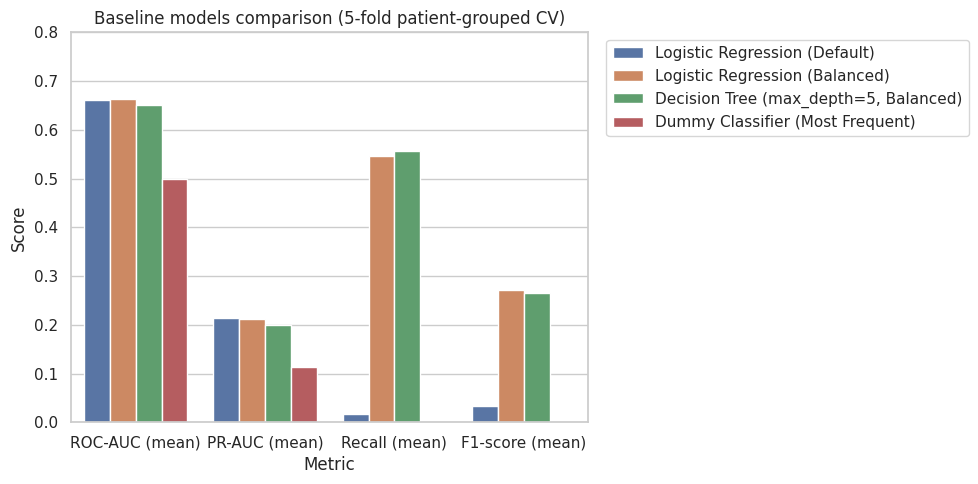

In [9]:
#put all cross-validation results in one table sorted by PR-AUC
summary_df = pd.DataFrame(cv_results).drop_duplicates(subset=["Model"]).sort_values(by="PR-AUC (mean)", ascending=False)
#display the summary table
display(summary_df)

#reshape the table to plot the main metrics side by side
plot_df = summary_df.melt(
    id_vars="Model",
    value_vars=["ROC-AUC (mean)", "PR-AUC (mean)", "Recall (mean)", "F1-score (mean)"],
    var_name="Metric",
    value_name="Score"
)

#create the figure
plt.figure(figsize=(10, 5))
#draw the grouped bar chart
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model")
#add title and limits
plt.title("Baseline models comparison (5-fold patient-grouped CV)")
plt.ylim(0, 0.80)
#place the legend outside the plot
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
#avoid overlapping texts
plt.tight_layout()
#display the chart
plt.show()

What this code does: we gather the 5-fold cross-validation results of all baseline models into a single table and we plot their main metrics side by side.

How to read the results: Logistic Regression (Balanced) gives the best overall balance across all metrics, with the highest ROC-AUC (0.6627), the highest F1-score (0.2718) and a PR-AUC of 0.2128 that nearly doubles the Dummy Classifier (0.1134). We select it as our primary reference baseline for the test evaluation below and for the model comparisons in Week 3.

# Part 3 - Test evaluation and feature inspection
In this part we evaluate our selected baseline on the held-out test set and we inspect the main features it uses.

## 8. Evaluation on the held-out test set

Test ROC-AUC   : 0.6547
Test PR-AUC    : 0.2096
Test Recall    : 0.5515
Test Precision : 0.1807
Test F1-score  : 0.2722


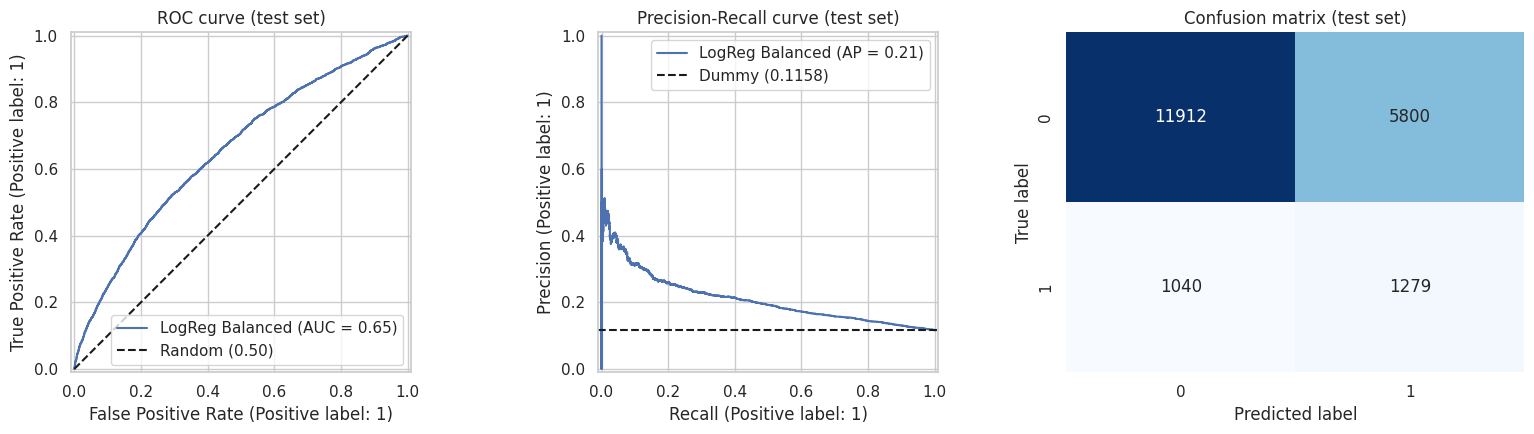

In [10]:
#fit the selected primary baseline on the full training set
best_baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
best_baseline.fit(X_train, y_train)

#predict probabilities and binary classes on the untouched test set
y_test_proba = best_baseline.predict_proba(X_test)[:, 1]
y_test_pred = best_baseline.predict(X_test)

#print the main evaluation metrics on the test set
print("Test ROC-AUC   :", round(roc_auc_score(y_test, y_test_proba), 4))
print("Test PR-AUC    :", round(average_precision_score(y_test, y_test_proba), 4))
print("Test Recall    :", round(recall_score(y_test, y_test_pred), 4))
print("Test Precision :", round(precision_score(y_test, y_test_pred), 4))
print("Test F1-score  :", round(f1_score(y_test, y_test_pred), 4))

#create a figure with three subplots: ROC curve, Precision-Recall curve and confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

#plot the ROC curve
RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=axes[0], name="LogReg Balanced")
axes[0].plot([0, 1], [0, 1], "k--", label="Random (0.50)")
axes[0].set_title("ROC curve (test set)")
axes[0].legend()

#plot the Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=axes[1], name="LogReg Balanced")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Dummy ({y_test.mean():.4f})")
axes[1].set_title("Precision-Recall curve (test set)")
axes[1].legend()

#plot the confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set_xlabel("Predicted label")
axes[2].set_ylabel("True label")
axes[2].set_title("Confusion matrix (test set)")

#avoid overlapping texts
plt.tight_layout()
#display the plots
plt.show()

What this code does: we fit our selected baseline model (Logistic Regression with balanced class weights) on the entire training set and we evaluate it once on the untouched test set. We also draw the ROC curve, the Precision-Recall curve and the confusion matrix.

How to read the results: the test scores (ROC-AUC = 0.6547, PR-AUC = 0.2096, F1-score = 0.2722) are very close to the 5-fold cross-validation averages (0.6627, 0.2128 and 0.2718). This confirms that splitting by patient prevented data leakage and that the model generalizes well without overfitting. Looking at the confusion matrix, the model catches 1,279 out of 2,319 early readmissions (recall = 0.5515), while generating 5,800 false positives out of 17,712 non-readmitted stays. Improving this precision-recall trade-off is the main objective for our advanced models in Week 3.

## 9. Top baseline feature coefficients

,Feature,Coefficient
28,cat__discharge_disposition_id_22,0.946158
29,cat__discharge_disposition_id_25,-0.709768
32,cat__discharge_disposition_id_5,0.604276
25,cat__discharge_disposition_id_1,-0.480789
57,cat__medical_specialty_Surgery-Cardiovascular/...,-0.478041
51,cat__medical_specialty_ObstetricsandGynecology,-0.469724
78,cat__diag_2_Neoplasms,0.370574
6,num__number_inpatient,0.355219
53,cat__medical_specialty_Orthopedics-Reconstructive,-0.329401
43,cat__admission_source_id_infrequent_sklearn,0.300697


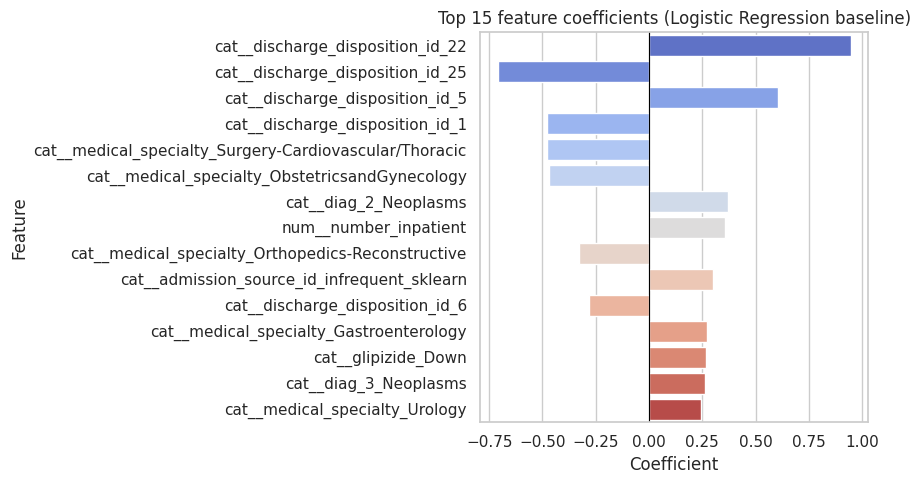

In [11]:
#put feature names and their learned weights in a table
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_baseline.coef_[0],
    "Abs_Coefficient": np.abs(best_baseline.coef_[0])
}).sort_values(by="Abs_Coefficient", ascending=False)

#keep the 15 strongest features
top_features = coef_df.head(15)
#display the table
display(top_features[["Feature", "Coefficient"]])

#create the figure
plt.figure(figsize=(9, 5))
#draw a horizontal bar chart of the top coefficients
sns.barplot(data=top_features, x="Coefficient", y="Feature", hue="Feature", palette="coolwarm", legend=False)
#add a vertical line at zero
plt.axvline(0, color="black", linewidth=0.8)
#add a title
plt.title("Top 15 feature coefficients (Logistic Regression baseline)")
#avoid overlapping texts
plt.tight_layout()
#display the chart
plt.show()

What this code does: we extract the 15 largest positive and negative coefficients learned by our Logistic Regression baseline so we can check which features drive the predictions.

How to read the results: discharge destination codes have the strongest impact on early readmission risk. Patients discharged to a rehabilitation facility (discharge_disposition_id_22, coefficient +0.946) or to another inpatient care facility (discharge_disposition_id_5, +0.604) have a much higher predicted risk, whereas patients discharged home (discharge_disposition_id_1, -0.481) are less likely to return within 30 days. Prior inpatient visits (number_inpatient, +0.355) and secondary neoplasm diagnoses (diag_2_Neoplasms, +0.371) also increase readmission risk. These results are medically coherent and give us a solid reference benchmark before testing non-linear models and feature selection in Week 3.